### Import libraries and also define variables

In [ ]:
#Mitchell Moffitt
#Preprocessing done - 10/11/2026
#Model done with fake data - 10/20/2026


import fennec_ml as fn                     # Folder cleaner, code posted on github: also use pip install fennec_ml to use
import torch                               # PyTorch: tensors, GPU support, and automatic gradients for training
import torch.nn as nn                      # building blocks for models: layers (Linear, Conv1d, LSTM) and losses (MSELoss)
import torch.nn.functional as F            # the same operations as plain functions: F.relu, F.mse_loss, F.dropout
import os                                  # file paths and folders: os.path.join, os.listdir, os.makedirs
import json                                # save and load settings or results as .json (config, metrics, label maps)
from torch.utils.data import TensorDataset, DataLoader
                                           # TensorDataset pairs each window with its target;
                                           # DataLoader hands them to the model in shuffled batches
import glob                                # find files by pattern, e.g. glob.glob("Raw_data/*.xlsx")
import re                                  # regular expressions, used to check filename formats like "0.15A"
import matplotlib.pyplot as plt            # plotting: loss curves, predicted vs true CG, flight signals

#Check Pytorch Version
torch.__version__

'2.14.0+cpu'

### Processing data

Open folder config and load the necessary configuration files for data processing.

In [ ]:
# --- FOLDER CONFIG ---
#MAKE SURE THESE ARE CORRECT
# 1. Set file path
DATA_dir = r"C:\Users\Mitch\OneDrive - LeTourneau University\Andrew Davis's files - Project FENNEC\FENNEC 2026-2027\Data Science Team\Mitchell Moffitt\Python Code\Jupyter Notebooks\GOAL 3- Data preprocessing"
# 2. Set folders taht are in that file path, one for raw data from the FENNEC clipper and one for processed data after it is turned into a csv
excel_dir = os.path.join(DATA_dir, "Raw_data_realistic")        # old fake data: "Raw_data"
csv_dir = os.path.join(DATA_dir, "Processed_data_realistic")     # old fake data: "Processed_data"
os.makedirs(csv_dir, exist_ok=True)   # keep each processed set in its own folder so they never mix

# --- MAKE VARS OF INTEREST ---
base_dir = os.getcwd()
json_path = os.path.join(base_dir, "1D_Variable_vars_of_interest.json")

# Data to write - add or remove as needed
vars_of_interest = { #Would I be better to use other vars of intrest if so which ones and why? How would each variable contribute to my model? Would i have to change the code if I add more or take away soem avriables of interest?
    "IMU_0": ['GyrX', 'GyrY', 'GyrZ', 'AccX', 'AccY', 'AccZ'],
    "RCOU": ['C1','C2','C3','C4'],
    #"ATT": ["Roll","Pitch","Yaw"],
    #"ATT": ["DesRoll","Roll","DesPitch","Pitch","DesYaw","Yaw","ErrRP","ErrYaw"],
    "RATE": ["RDes","R","ROut","PDes","P","POut","YDes","Y","YOut"], # Not sure but could have been 88% acuracy
    #"VIBE_0": ["VibeX", "VibeY", "VibeZ"],
    #"VIBE_1": ["VibeX", "VibeY", "VibeZ"]
}

# Counted from the dict so it always matches the CSV columns (was hardcoded to 6, but there are 19)
INPUT_CHANNELS = sum(len(cols) for cols in vars_of_interest.values())

# Write to JSON file
with open(json_path, "w") as f:
    json.dump(vars_of_interest, f, indent=4)

print(f"Created {json_path}")
print(f"INPUT_CHANNELS = {INPUT_CHANNELS}")

Created c:\Users\Mitch\OneDrive - LeTourneau University\Andrew Davis's files - Project FENNEC\FENNEC 2026-2027\Data Science Team\Mitchell Moffitt\Python Code\Jupyter Notebooks\GOAL 4 - Put code together\1D_Variable_vars_of_interest.json
INPUT_CHANNELS = 19


* Write to CSV file
* also cleans up data so that the model cannot get confused by all of the other data that a flight controller collects

In [ ]:
# --- EXCEL TO CSV ---
#Remember to clear out the old data before writing more to the processed data
answer = input("Run excel to csv? (1 for yes, 0 for no): ")
if answer.strip() == "1":     # input() returns a string; the old `answer := 1` assigned 1 and was always True
    print("Using folder_cleaner() to convert from raw excel files to useful .csv's.\nfolder_cleaner() output:")

    print("Running folder_cleaner...")
    #Takes from the raw excel files in excel_dir and writes processed CSVs to csv_dir
    # downsample=True keeps every 5th IMU/RATE row (50 Hz) so they line up in time with RCOU (10 Hz).
    # downsample=False is broken in fennec_ml: RCOU never gets upsampled, then everything is cut to the
    # RCOU length, so each CSV pairs the first ~20% of the IMU data with the whole flight's servo data.
    fn.folder_cleaner(excel_dir, csv_dir, overwrite= True, varspath="1D_Variable_vars_of_interest.json", downsample=True)
    print("folder_cleaner finished")
# explain how the folder cleaner works and what downsample does? ANd why do I need it set to true? IS it because I am using data from multiple sensors?
else: 
    print(f"All data is already in the data_processed folder")

All data is already in the data_processed folder


This Section uses the Variable_CG_Preprocessing file I created

It does these things:

* Splits data into train/validation/test set for appropriate model training
* Imports normalizer so that the differing units do nto skew the data such as the gyro adn the accelrometer have different magnitubes of numbers and it breaks it down into the mean the std so that the data will not be skewed
* Then it segments the data, since there are so many timesteps per flight this makes it so that the model trains on evenly split portions or windows of data (which is needed), it will divide the data up into a certain amount of timesteps and send that chunk of data into the model
* The data loader feeds your windows to the model in small batches during training. It does the bookkeeping that you would otherwise write by hand.

### Augmentation/ noise

Should this be added?
    * For now i will assume the data on its own will have enough noise due to real world error


For splitting data: Will i need to train a model on every single peice of data we gather at once (80-0-20 split) or will that be too much data and will i need to use the code below to only take a cer tain amount of data points. 

TEST THIS ONCE I HAVE DATA AND COMAPARE THE RESULTS

In [ ]:

from Variable_CG_Preprocessing import Flight_Objects_Var, FlightDataNormalizer_Var, FlightDataSegmenter_Var
from collections import Counter
from Variable_CG_Preprocessing import split_flights_by_fraction, make_dataloader_Var

flights1 = Flight_Objects_Var(csv_dir)          # load once

counts = Counter(f.cg_code for f in flights1.flights)
minimum = min(counts.values()) #what is the purpose of this?

#This does a 70-15-15 split of the flights into train, val, and test sets
# The validation set picks the best epoch and drives the LR scheduler.
# The test set is only looked at once, at the very end, so its score is honest.
train_frac = 0.7 # Why is this a good split?
val_frac = 0.15

train_flights, val_flights, test_flights = split_flights_by_fraction(
    flights1, train_frac=train_frac, val_frac=val_frac
)

print("Number of train flights:", len(train_flights))
print("Number of val flights:", len(val_flights))
print("Number of test flights:", len(test_flights))

# Data normilzer
normalizer = FlightDataNormalizer_Var()

# Fit norm on train data, then apply to val/test
train_flights = normalizer.fit_transform(train_flights) #Expalin fit.transform.

# Transfrom to Val/Test
val_flights = normalizer.transform(val_flights)
test_flights = normalizer.transform(test_flights)

SEGMENT_LENGTH = 200  # rows per window; at 10 Hz this is 20 s of flight #Is this a good segment length? Is so why? and if not why not?
# Must be shorter than the shortest flight or that flight gives zero windows
# (550 was longer than every 450-row flight, which caused "min() iterable argument is empty")
segment_length = SEGMENT_LENGTH       # keep whatever you set earlier
stride = segment_length     # no overlap; use segment_length // 2 for 50% overlap #What does this do?

shortest = min(f.data.shape[0] for f in flights1.flights)
if shortest < segment_length:
    raise ValueError(f"SEGMENT_LENGTH={segment_length} is longer than the shortest flight ({shortest} rows)")

def n_windows(flight):
    """How many windows fit in this flight at the chosen length and stride."""
    n = flight.data.shape[0]
    return (n - segment_length) // stride + 1 if n >= segment_length else 0

# Smallest flight (in windows) in each split, used to balance flights within the split
train_min_segments_per_flight = min(n_windows(f) for f in train_flights)
val_min_segments_per_flight = min(n_windows(f) for f in val_flights)
test_min_segments_per_flight = min(n_windows(f) for f in test_flights)

print("Smallest flight in training set (windows):", train_min_segments_per_flight)
print("Smallest flight in validation set (windows):", val_min_segments_per_flight)
print("Smallest flight in testing set (windows):", test_min_segments_per_flight)

# Separate segmenters so each split is internally balanced
train_segmenter = FlightDataSegmenter_Var( #Does this make it to where i dont train it in whole flights? If so waht is the advantage of segmenting the data rather than a whoel flight?
    #Would it be too much data at once to train on the whole flight or will thsi improve the real world applications?
    segment_length=segment_length,
    stride=stride,
    max_segments_per_flight=train_min_segments_per_flight,
    seed=42,
)
val_segmenter = FlightDataSegmenter_Var(
    segment_length=segment_length,
    stride=stride,
    max_segments_per_flight=val_min_segments_per_flight,
    seed=42,
)
test_segmenter = FlightDataSegmenter_Var(
    segment_length=segment_length,
    stride=stride,
    max_segments_per_flight=test_min_segments_per_flight,
    seed=42,
)

# Returns: windows, scaled CG targets, and which flight each window came from
train_segments, train_targets, train_flight_idx = train_segmenter.segment_flights(train_flights)
val_segments, val_targets, val_flight_idx = val_segmenter.segment_flights(val_flights)
test_segments, test_targets, test_flight_idx = test_segmenter.segment_flights(test_flights)

# Check shapes
print("Train segments:", train_segments.shape)    # (N, L, F)
print("Train targets: ", train_targets.shape)     # (N,)
print("Val segments:  ", val_segments.shape)
print("Test segments: ", test_segments.shape)
print("Test targets:  ", test_targets.shape)

# Data loaders
batch_size = 32 #Is this a good batch size? If so why? and if not why not?

train_loader = make_dataloader_Var(train_segments, train_targets, batch_size=batch_size, shuffle=True)
val_loader = make_dataloader_Var(val_segments, val_targets, batch_size=batch_size, shuffle=False)
test_loader = make_dataloader_Var(test_segments, test_targets, batch_size=batch_size, shuffle=False)

print(f"Number of batches in train loader: {len(train_loader)}")
print(f"Number of batches in val loader: {len(val_loader)}")
print(f"Number of batches in test loader: {len(test_loader)}")

#if ur seeing this then ur cool - mitchell

Number of train flights: 67
Number of val flights: 12
Number of test flights: 21
Scaler fitted: mean shape (19,) var shape (19,)
Scaler fitted on training data:
Feature 0: mean = 0.0086, std = 0.2431
Feature 1: mean = 0.0039, std = 0.2547
Feature 2: mean = -0.0169, std = 0.7115
Feature 3: mean = -0.1447, std = 0.7509
Feature 4: mean = -0.3540, std = 0.6854
Feature 5: mean = -9.8838, std = 0.9113
Feature 6: mean = 1491.4193, std = 40.8775
Feature 7: mean = 1672.3893, std = 39.0234
Feature 8: mean = 1660.5196, std = 40.9213
Feature 9: mean = 1473.3762, std = 33.7556
Feature 10: mean = 0.5825, std = 13.5855
Feature 11: mean = 0.4797, std = 13.7059
Feature 12: mean = 0.0059, std = 0.0575
Feature 13: mean = 0.2396, std = 14.0846
Feature 14: mean = 0.2479, std = 14.3713
Feature 15: mean = 0.0022, std = 0.0614
Feature 16: mean = -1.8870, std = 40.8578
Feature 17: mean = -0.9750, std = 40.6603
Feature 18: mean = -0.0227, std = 0.0860
Smallest flight in training set (windows): 3
Smallest flight

This code below is basically so that the whole entire data set does not need to be used at once and the model can be trained on smaller data sets like 44 training flights and 11 test flights rather than an 80-0-20 split on over 100 data points

In [38]:
#EXTRA CODE DO NOT RUN

# from Variable_CG_Preprocessing import split_flights_by_class

# train_per_class = 3 #asks for 3 flights per CG position (so 11 postions * 3 = 33 flights for training)
# val_per_class = 0 #asks for 0 flights per CG position for validation

# train_flights, val_flights, test_flights = split_flights_by_class(flights1,train_per_class=train_per_class, val_per_class=val_per_class)
# print(f"Number of training flights: {len(train_flights)}")
# print(f"Number of val flights: {len(val_flights)}")
# print(f"Number of testing flights: {len(test_flights)}")

This tells us the duration fo each flight with full segments

In [ ]:
n_show = 5   # how many flights to print from each split
#Does this just display to useable segments from each flight that the maodel can be trained on?
print(f"Train: showing {n_show} of {len(train_flights)} flights")
for i, f in enumerate(train_flights[:n_show]):
    print(f"  Flight {i} ({f.filename}): {f.data.shape[0] // segment_length} full segments")

print(f"\nTest: showing {n_show} of {len(test_flights)} flights")
for i, f in enumerate(test_flights[:n_show]):
    print(f"  Flight {i} ({f.filename}): {f.data.shape[0] // segment_length} full segments")

Train: showing 5 of 67 flights
  Flight 0 (306B_0.60A_L.csv): 5 full segments
  Flight 1 (332B_0.60A_L.csv): 3 full segments
  Flight 2 (367B_0.60A_H.csv): 6 full segments
  Flight 3 (326B_0.60A_H.csv): 5 full segments
  Flight 4 (386B_0.60A_M.csv): 3 full segments

Test: showing 5 of 21 flights
  Flight 0 (300B_0.60A_M.csv): 5 full segments
  Flight 1 (301B_0.60A_H.csv): 5 full segments
  Flight 2 (304B_0.75F_L.csv): 5 full segments
  Flight 3 (396B_0.75F_M.csv): 3 full segments
  Flight 4 (305B_0.30A_M.csv): 4 full segments


Checks Normalization: Mean and Standard Deviation

In [40]:
import numpy as np

# X_train_segments is your list/array of training segments (num_segments, seq_len, num_features)
X_train = np.concatenate(train_segments, axis=0)  # flatten over segments

# Compute per-feature mean and std
feature_means = X_train.mean(axis=0)
feature_stds  = X_train.std(axis=0)

print("Per-feature mean after normalization:", feature_means)
print("Per-feature std after normalization:", feature_stds, "\n")

# Overall mean/std
print(f"Mean should be close to 0 and std should be close to 1")
print("Overall mean:", X_train.mean())
print("Overall std:", X_train.std())

Per-feature mean after normalization: [-0.00378752 -0.00995457 -0.00605922 -0.03599245  0.01840723  0.02421067
 -0.04945251 -0.05069541 -0.02827675  0.00803237  0.00781687 -0.00264702
  0.01789375 -0.00833793 -0.00966052 -0.00883853 -0.01052334 -0.0062813
  0.01557642]
Per-feature std after normalization: [0.8817027  0.8672371  0.84478134 0.9303809  0.93997353 0.9420021
 1.0395197  1.0496747  1.0438955  0.9652607  0.8855439  0.87911487
 0.91944134 0.87528294 0.86529595 0.8814566  0.8547865  0.8441923
 0.8861445 ] 

Mean should be close to 0 and std should be close to 1
Overall mean: -0.007293145
Overall std: 0.91808176


### Check data segmentation
* make sure each offset has equal representation

In [ ]:
from collections import Counter
from Variable_CG_Preprocessing import unscale_target

#Is this needed? What happens if they do not have equal representation? 
def cg_distribution(targets_scaled):
    """Count windows per CG offset (inches), sorted aft (-) to forward (+)."""
    inches = np.round(unscale_target(targets_scaled), 2)
    return dict(sorted(Counter(inches.tolist()).items()))

print("Train CG distribution (windows per offset, in):")
for cg, n in cg_distribution(train_targets).items():
    print(f"  {cg:+.2f}: {n}")

print("\nTest CG distribution (windows per offset, in):")
for cg, n in cg_distribution(test_targets).items():
    print(f"  {cg:+.2f}: {n}")

Train CG distribution (windows per offset, in):
  -0.75: 18
  -0.60: 18
  -0.45: 18
  -0.30: 18
  -0.15: 18
  +0.00: 21
  +0.15: 18
  +0.30: 18
  +0.45: 18
  +0.60: 18
  +0.75: 18

Test CG distribution (windows per offset, in):
  -0.75: 6
  -0.60: 6
  -0.45: 6
  -0.30: 6
  -0.15: 6
  +0.00: 3
  +0.15: 6
  +0.30: 6
  +0.45: 6
  +0.60: 6
  +0.75: 6


In [ ]:
#Variables (Hyperparameters)

SEED = 42 #For reproducibility

#Sets the amount of neurons per layer
HIDDEN_LAYER1 = 100
HIDDEN_LAYER2 = 100 #How many layers is optimal and why?
HIDDEN_LAYER3 = 10  #I dont use htis but more can be added

INPUT_FEATURES = SEGMENT_LENGTH * INPUT_CHANNELS
OUTPUT_FEATURES = 1 #Number of output features (CG prediction in 1D)

EPOCHS = 150  # Number of training epochs #Should i add a stop after a certain amount of plateau or no imporvment?
LR = 0.0001
WEIGHT_DECAY = 1e-2 #HOW SHOULD I SET THIS?
DROPOUT_RATE1 = 0.1 #Are these good dropout rates and why?
DROPOUT_RATE2 = 0.3


### Build model

- nn.Linear: creates multiple layers that can help the model be more trainable

This will be the first model I train and then useign the exact same data I will train a nn.sequential model to test  how it comapres with more fancy layers

Should i add nonlinearity to the model? :

self.net = nn.Sequential(
    nn.Linear(INPUT_FEATURES, HIDDEN_LAYER1), nn.ReLU(), nn.Dropout(DROPOUT_RATE1),
    nn.Linear(HIDDEN_LAYER1, HIDDEN_LAYER2),  nn.ReLU(), nn.Dropout(DROPOUT_RATE2),
    nn.Linear(HIDDEN_LAYER2, OUTPUT_FEATURES),
)
self.linear_layer1 = nn.Linear(in_features = INPUT_FEATURES, out_features = HIDDEN_LAYER1)
        self.linear_layer2 = nn.Linear(in_features = HIDDEN_LAYER1, out_features = HIDDEN_LAYER2)
        self.linear_layer3 = nn.Linear(in_features = HIDDEN_LAYER2, out_features = OUTPUT_FEATURES)


In [ ]:
# Create a linear regression model class
class LinearRegressionModelV0(nn.Module): # almost everything in Pytorch inherits it from nn.Module
    def __init__(self, INPUT_FEATURES, HIDDEN_LAYER1, HIDDEN_LAYER2, OUTPUT_FEATURES, DROPOUT_RATE1, DROPOUT_RATE2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(INPUT_FEATURES, HIDDEN_LAYER1), nn.ReLU(), nn.Dropout(DROPOUT_RATE1),
            nn.Linear(HIDDEN_LAYER1, HIDDEN_LAYER2),  nn.ReLU(), nn.Dropout(DROPOUT_RATE2),
            nn.Linear(HIDDEN_LAYER2, OUTPUT_FEATURES)) #Should the model be organized differntly or even purely linear? is this an ok assumption?

    #Forward method to define the computation in the model
    def forward(self, x: torch.Tensor) -> torch.Tensor: #x is the input data
        x = x.flatten(start_dim=1)
        return self.net(x)

The random seed only applies to the random parameters

In [ ]:
# Create random seed for reproducibility
torch.manual_seed(SEED) #sets intial conditions biscally, create repeatibility

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#Create instance of the model (this is a subclass of nn.module)
LRModel = LinearRegressionModelV0(
    INPUT_FEATURES = INPUT_FEATURES, 
    HIDDEN_LAYER1 = HIDDEN_LAYER1, 
    HIDDEN_LAYER2 = HIDDEN_LAYER2, 
    OUTPUT_FEATURES = OUTPUT_FEATURES,
    DROPOUT_RATE1 = DROPOUT_RATE1,
    DROPOUT_RATE2 = DROPOUT_RATE2).to(device)


#CHeck out parameters
list(LRModel.parameters())

#Create loss
loss_fn = nn.MSELoss() #Should i use a differnt loss function? if yes then why? is not then why?

#Create optimizer
#Adam defaults weight decay to 0, so AdamW is used to explicitly set it
optimizer = torch.optim.AdamW(LRModel.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
# Should I use a different optimizer? if yes then why? is not then why?

#This is useful for training plauteaus
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau( # Should I use a scheduler? if yes then why? is not then why?
    optimizer,
    mode="min",
    factor=0.1, #How much it cuts the lr down by
    patience=10 #Number of epochs with no improvement after which the learning rate will be reduced
)
#The scheduler will reduce the learning rate when the validation loss plateaus

In [48]:
def evaluate(LRModel, loader, loss_fn, device):

    LRModel.eval()                              # turns off dropout, batch-norm uses running stats

    total_loss, total_abs_err, total_samples = 0.0, 0.0, 0

    with torch.inference_mode():              # no gradients, faster and uses less memory
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            pred = LRModel(X_batch).view_as(y_batch)   # (B, 1), same shape as the targets
            loss = loss_fn(pred, y_batch)

            bs = X_batch.size(0)
            total_loss += loss.item() * bs
            # MAE in inches (targets are scaled to [-1, 1] by CG_MAX)
            total_abs_err += (pred - y_batch).abs().sum().item() * CG_MAX
            total_samples += bs

    avg_loss = total_loss / total_samples
    mae_in = total_abs_err / total_samples
    return avg_loss, mae_in




evaluate(LRModel, test_loader, loss_fn, device)
print(f"Model in training mode: {LRModel.training}") 

Model in training mode: False


### Training loop

In [ ]:
from Variable_CG_Preprocessing import CG_MAX, CG_STEP

save_dir = "saved_models"
os.makedirs(save_dir, exist_ok=True)
best_path = os.path.join(save_dir, "Best_1DVar_Model.pth")
scaler_path = os.path.join(save_dir, "scaler.pkl")

# Save the scaler this model was trained with, so CG_Predict_Deploy.ipynb always normalizes
# new flights the same way. Overwritten on every training run, together with the model.
import pickle
with open(scaler_path, "wb") as f:
    pickle.dump(normalizer.scaler, f)

CLIP = 1.0                      # max gradient norm
best_val_mae = float("inf")
best_epoch = -1
history = {"train_loss": [], "val_loss": [], "train_mae": [], "val_mae": []}

for epoch in range(EPOCHS):
    LRModel.train()             # dropout on, gradients tracked
    total_loss = 0.0
    total_abs_err = 0.0
    total_samples = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)                 # (B, 1), scaled to [-1, 1]

        optimizer.zero_grad()                        # clear old gradients
        pred = LRModel(X_batch).view_as(y_batch)     # (B, 1)
        loss = loss_fn(pred, y_batch)

        loss.backward()                              # compute gradients
        torch.nn.utils.clip_grad_norm_(LRModel.parameters(), CLIP) #What does this do?
        optimizer.step()                             # update weights

        bs = X_batch.size(0)
        total_loss += loss.item() * bs
        total_abs_err += (pred - y_batch).abs().sum().item() * CG_MAX
        total_samples += bs

    avg_train_loss = total_loss / total_samples
    train_mae = total_abs_err / total_samples

    # Validation (not test) drives the scheduler and the checkpoint, so the test set stays unseen
    avg_val_loss, val_mae = evaluate(LRModel, val_loader, loss_fn, device)
    scheduler.step(avg_val_loss)                     # lowers LR if loss plateaus

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["train_mae"].append(train_mae)
    history["val_mae"].append(val_mae)

    if val_mae < best_val_mae:                       # keep the best model
        best_val_mae = val_mae
        best_epoch = epoch + 1
        torch.save(LRModel.state_dict(), best_path)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {avg_train_loss:.4f} | Train MAE: {train_mae:.3f} in | "
        f"Val Loss: {avg_val_loss:.4f} | Val MAE: {val_mae:.3f} in | "
        f"LR: {optimizer.param_groups[0]['lr']:.5f}"
    )

print(f"\nBest val MAE: {best_val_mae:.3f} in at epoch {best_epoch}")

LRModel.load_state_dict(torch.load(best_path, map_location=device))
LRModel.to(device)
LRModel.eval()

# Score the test set exactly once, with the model chosen on validation
test_loss, test_mae = evaluate(LRModel, test_loader, loss_fn, device)
print(f"Test MAE (unseen flights): {test_mae:.3f} in")

Epoch [1/150] | Train Loss: 0.4022 | Train MAE: 0.408 in | Val Loss: 0.3184 | Val MAE: 0.355 in | LR: 0.00010
Epoch [2/150] | Train Loss: 0.3032 | Train MAE: 0.355 in | Val Loss: 0.2876 | Val MAE: 0.334 in | LR: 0.00010
Epoch [3/150] | Train Loss: 0.2485 | Train MAE: 0.317 in | Val Loss: 0.2548 | Val MAE: 0.312 in | LR: 0.00010
Epoch [4/150] | Train Loss: 0.2120 | Train MAE: 0.288 in | Val Loss: 0.2232 | Val MAE: 0.286 in | LR: 0.00010
Epoch [5/150] | Train Loss: 0.1744 | Train MAE: 0.255 in | Val Loss: 0.1920 | Val MAE: 0.254 in | LR: 0.00010
Epoch [6/150] | Train Loss: 0.1358 | Train MAE: 0.223 in | Val Loss: 0.1720 | Val MAE: 0.236 in | LR: 0.00010
Epoch [7/150] | Train Loss: 0.1215 | Train MAE: 0.209 in | Val Loss: 0.1615 | Val MAE: 0.227 in | LR: 0.00010
Epoch [8/150] | Train Loss: 0.1035 | Train MAE: 0.194 in | Val Loss: 0.1533 | Val MAE: 0.217 in | LR: 0.00010
Epoch [9/150] | Train Loss: 0.1041 | Train MAE: 0.180 in | Val Loss: 0.1476 | Val MAE: 0.213 in | LR: 0.00010
Epoch [10/

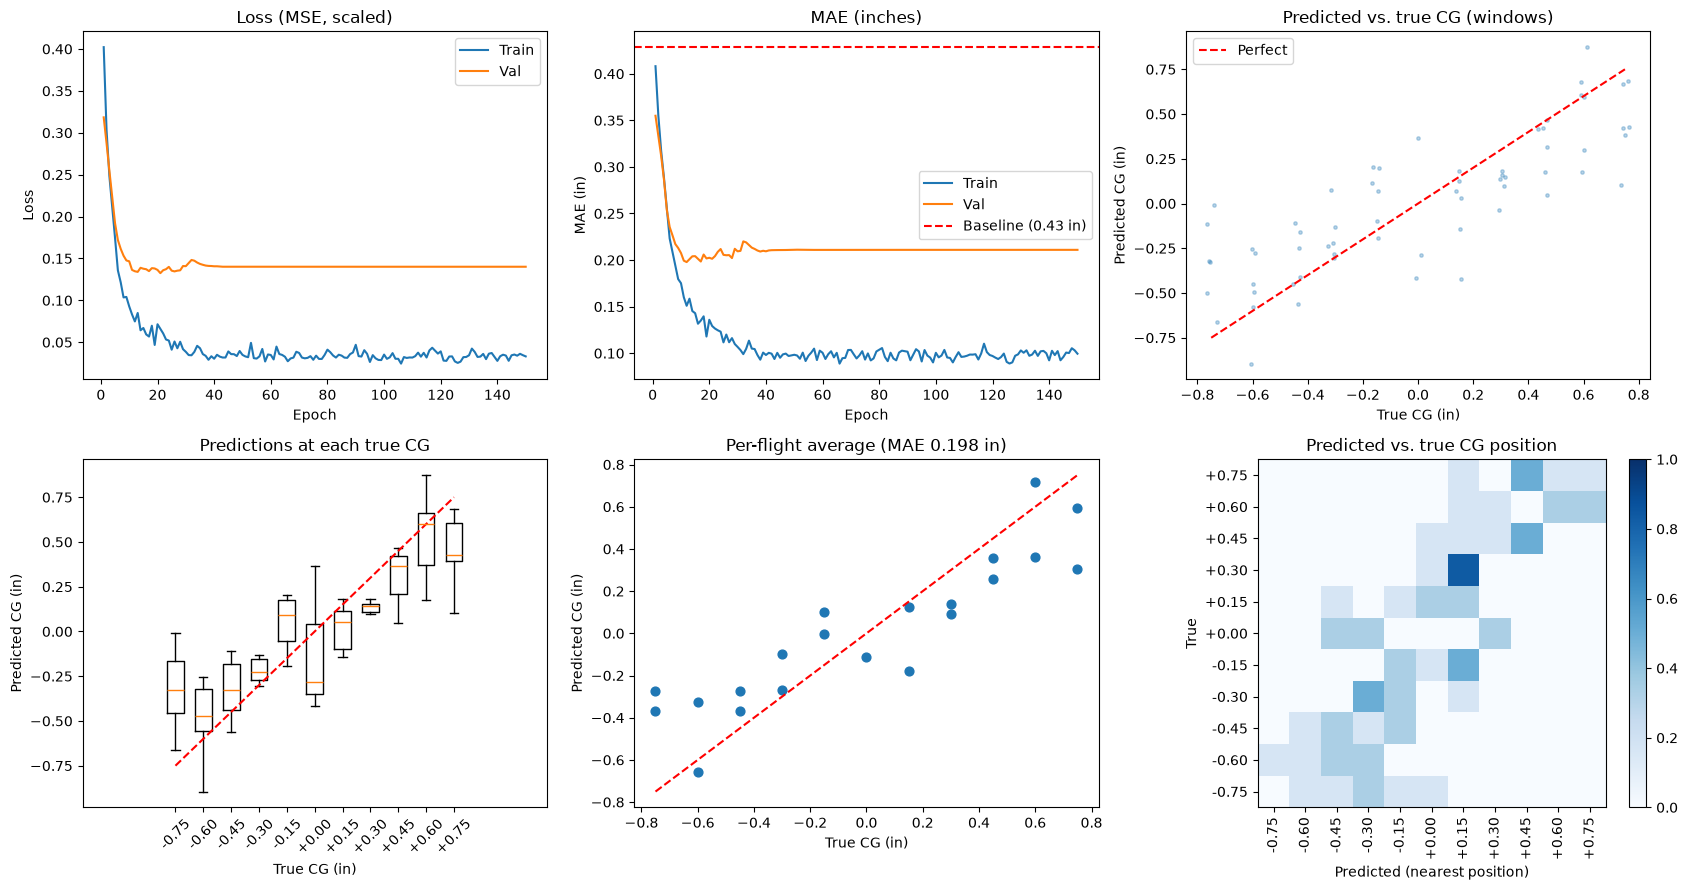

Window MAE: 0.220 in | Baseline: 0.429 in | Per-flight MAE: 0.198 in


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from Variable_CG_Preprocessing import unscale_target, CG_MAX, CG_STEP

# ---------- Collect predictions (test_loader has shuffle=False, so order matches test_targets) ----------
LRModel.eval()
preds = []
with torch.inference_mode():
    for X_batch, _ in test_loader:
        preds.append(LRModel(X_batch.to(device)).cpu().numpy())
pred_in = unscale_target(np.concatenate(preds).ravel())      # predicted CG, inches
true_in = unscale_target(test_targets)                       # true CG, inches
err = pred_in - true_in

BASELINE_MAE = np.mean(np.abs(true_in))                      # MAE of always predicting 0
cg_levels = np.round(np.arange(-CG_MAX, CG_MAX + 1e-9, CG_STEP), 2) #Why the 1e-9?? What is the purpose of thsi line?

# Panels 3-6 below use the TEST set (scored once, after training)
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
ax = axes.ravel()

# 1) Learning curves: loss
ep = np.arange(1, len(history["train_loss"]) + 1)
ax[0].plot(ep, history["train_loss"], label="Train") #Explain how these types of plots work and why you dont use plt.plot
ax[0].plot(ep, history["val_loss"], label="Val") #Explain the history function used here
ax[0].set(title="Loss (MSE, scaled)", xlabel="Epoch", ylabel="Loss")
ax[0].legend()

# 2) Learning curves: MAE vs. the "always predict 0" baseline
ax[1].plot(ep, history["train_mae"], label="Train")
ax[1].plot(ep, history["val_mae"], label="Val")
ax[1].axhline(BASELINE_MAE, color="red", ls="--", label=f"Baseline ({BASELINE_MAE:.2f} in)")
ax[1].set(title="MAE (inches)", xlabel="Epoch", ylabel="MAE (in)")
ax[1].legend()

# 3) Predicted vs. true, per window
jitter = np.random.default_rng(0).normal(0, 0.012, size=true_in.shape)
ax[2].scatter(true_in + jitter, pred_in, s=6, alpha=0.3)
ax[2].plot([-CG_MAX, CG_MAX], [-CG_MAX, CG_MAX], "r--", label="Perfect")
ax[2].set(title="Predicted vs. true CG (windows)", xlabel="True CG (in)", ylabel="Predicted CG (in)")
ax[2].legend()

# 4) Prediction spread at each true CG position
data = [pred_in[np.isclose(true_in, c, atol=1e-3)] for c in cg_levels]
ax[3].boxplot(data, positions=cg_levels, widths=CG_STEP * 0.6, showfliers=False)
ax[3].plot([-CG_MAX, CG_MAX], [-CG_MAX, CG_MAX], "r--")
ax[3].set(title="Predictions at each true CG", xlabel="True CG (in)", ylabel="Predicted CG (in)")
ax[3].set_xticks(cg_levels)
ax[3].set_xticklabels([f"{c:+.2f}" for c in cg_levels], rotation=45)

# 5) Per-flight averaged predictions (averages all windows from the same flight)
n_fl = test_flight_idx.max() + 1
fl_pred = np.bincount(test_flight_idx, weights=pred_in, minlength=n_fl) / np.bincount(test_flight_idx, minlength=n_fl)
fl_true = np.bincount(test_flight_idx, weights=true_in, minlength=n_fl) / np.bincount(test_flight_idx, minlength=n_fl)
ax[4].scatter(fl_true, fl_pred, s=40)
ax[4].plot([-CG_MAX, CG_MAX], [-CG_MAX, CG_MAX], "r--")
fl_mae = np.mean(np.abs(fl_pred - fl_true))
ax[4].set(title=f"Per-flight average (MAE {fl_mae:.3f} in)", xlabel="True CG (in)", ylabel="Predicted CG (in)")

# 6) Confusion heatmap: prediction snapped to the nearest CG position
#expalon how the heat map works line by line
snap = np.clip(np.round(pred_in / CG_STEP) * CG_STEP, -CG_MAX, CG_MAX)
ti = np.round((true_in + CG_MAX) / CG_STEP).astype(int)
pi = np.round((snap + CG_MAX) / CG_STEP).astype(int)
cm = np.zeros((len(cg_levels), len(cg_levels)))
for t, p in zip(ti, pi):
    cm[t, p] += 1
cm = cm / cm.sum(axis=1, keepdims=True)                      # each row sums to 1
im = ax[5].imshow(cm, cmap="Blues", origin="lower", vmin=0, vmax=1)
ax[5].set_xticks(range(len(cg_levels)))
ax[5].set_xticklabels([f"{c:+.2f}" for c in cg_levels], rotation=90)
ax[5].set_yticks(range(len(cg_levels)))
ax[5].set_yticklabels([f"{c:+.2f}" for c in cg_levels])
ax[5].set(title="Predicted vs. true CG position", xlabel="Predicted (nearest position)", ylabel="True")
fig.colorbar(im, ax=ax[5], fraction=0.046)

plt.tight_layout()
plt.show()

print(f"Window MAE: {np.mean(np.abs(err)):.3f} in | Baseline: {BASELINE_MAE:.3f} in | Per-flight MAE: {fl_mae:.3f} in")